# 01 · Data loading, cleaning and sanity checks

**Goal:** turn the raw IEA file into a clean, validated table I can trust for time-series analysis.

**Data:** IEA *World Energy Balances*, Total Energy Supply (TES) by source, World, 1990–2024, in terjoules (TJ).
Released under **CC BY 4.0** (attribution: IEA World Energy Balances, https://www.iea.org/data-and-statistics/data-product/world-energy-statistics-balances).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.energy import load_tes, validate, FOSSIL, RENEWABLES
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Look at the raw file before parsing
Opening the file in a text editor first shows it is **not** a plain CSV: two metadata lines (source and licence), a blank line, then the header, and the year column has no name.

In [2]:
with open("../data/raw/iea_tes_by_source_world.csv") as f:
    for i, line in zip(range(6), f):
        print(i, repr(line[:110]))

0 'Source: IEA World Energy Balances https://www.iea.org/data-and-statistics/data-product/world-energy-statistics'
1 'This data is released under a CC BY 4.0 licence: https://www.iea.org/terms/creative-commons-cc-licenses\n'
2 '\n'
3 ',Coal and coal products,Natural gas,Hydropower,Nuclear,"Solar, wind and other renewables",Biofuels and waste,O'
4 '1990,92902686,69606458,7715810,22002472,1533731,34995038,135409476,TJ\n'
5 '1991,90468571,71981029,7952758,23014695,1566624,35530676,135964577,TJ\n'


`pd.read_csv` on this file fails with a tokenizing error, because pandas expects the first line to define the number of columns. The fix is `skiprows=3` and naming the year column. This is wrapped in `src/energy.py::load_tes` so it is done once, tested, and reused.

In [3]:
ej = load_tes()          # wide table, index = year, values in EJ (1 EJ = 1,000,000 TJ)
ej.head()

source,Coal and coal products,Natural gas,Hydropower,Nuclear,"Solar, wind and other renewables",Biofuels and waste,Oil and oil products
year,,,,,,,
1990,92.90,69.61,7.72,22.00,1.53,35.00,135.41
1991,90.47,71.98,7.95,23.01,1.57,35.53,135.96
1992,88.96,72.04,7.96,23.20,1.64,36.25,136.77
1993,89.29,73.37,8.42,23.92,1.68,36.33,137.57
1994,90.08,73.35,8.50,24.49,1.76,36.82,138.45


## 2. Validation
Checks that would catch silent problems: gaps in years, missing values, non-positive values, unexpected units.

In [4]:
checks = validate(ej)    # raises AssertionError if any check fails
checks

{'n_years': 35,
 'year_range': (1990, 2024),
 'contiguous_years': True,
 'n_missing': 0,
 'all_positive': True}

## 3. Sanity checks on the numbers
- Total supply should grow broadly steadily, with dips only at known shocks (e.g. 2009 financial crisis, 2020 Covid-19).
- Year-on-year changes far outside the normal range would flag a unit or data error.

In [5]:
total = ej.sum(axis=1).rename("Total energy supply (EJ)")
yoy = total.pct_change() * 100
print(f"Total supply: {total.loc[1990]:.1f} EJ (1990) -> {total.loc[2024]:.1f} EJ (2024)")
print("Years with a fall in total supply:", list(yoy[yoy < 0].round(2).items()))
print("Largest YoY rise: %d (%.2f%%)" % (yoy.idxmax(), yoy.max()))

Total supply: 364.2 EJ (1990) -> 649.5 EJ (2024)
Years with a fall in total supply: [(2009, -1.01), (2020, -3.5)]
Largest YoY rise: 2021 (6.00%)


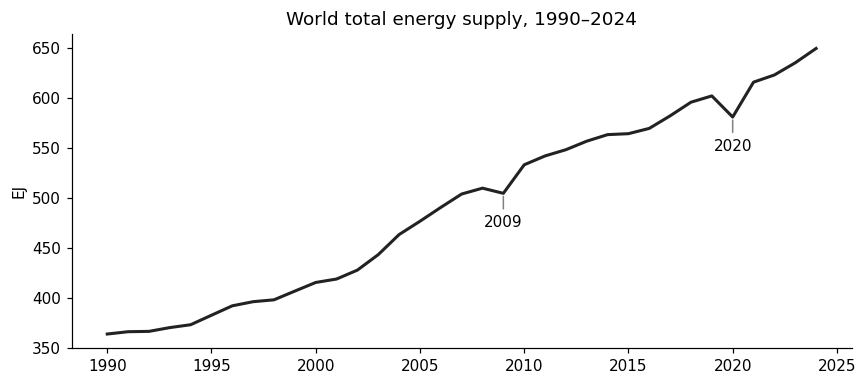

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(total.index, total.values, color="#222", lw=2)
for yr, lab in [(2009, "2009"), (2020, "2020")]:
    ax.annotate(lab, (yr, total.loc[yr]), xytext=(0, -22), textcoords="offset points", ha="center",
                arrowprops=dict(arrowstyle="-", color="grey"))
ax.set(title="World total energy supply, 1990–2024", ylabel="EJ", xlabel="")
plt.tight_layout(); plt.show()

Total supply dips exactly where expected (2009 and 2020), which gives confidence that the extract is internally consistent and the unit conversion is right.

## 4. Save tidy outputs
- `data/processed/tes_by_source_EJ.csv`: wide, EJ.
- `data/processed/tes_by_source_long.csv`: tidy/long format (year, source, EJ), convenient for plotting and modelling.

In [7]:
ej.to_csv("../data/processed/tes_by_source_EJ.csv")
(ej.reset_index().melt(id_vars="year", var_name="source", value_name="EJ")
   .to_csv("../data/processed/tes_by_source_long.csv", index=False))
print("saved:", ej.shape, "wide;", ej.shape[0] * ej.shape[1], "long rows")

saved: (35, 7) wide; 245 long rows


## 5. First look: what the world burned and harvested
Stacked area in absolute terms. Note this is **primary energy supply**, not electricity.

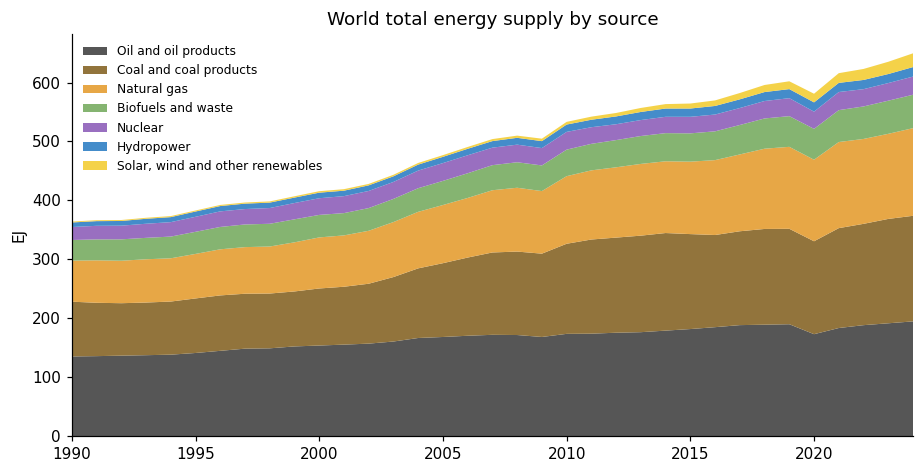

In [8]:
order = ["Oil and oil products", "Coal and coal products", "Natural gas", "Biofuels and waste",
         "Nuclear", "Hydropower", "Solar, wind and other renewables"]
colors = ["#4d4d4d", "#8c6d31", "#e6a23c", "#7fb069", "#9467bd", "#3a86c8", "#f4d03f"]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.stackplot(ej.index, [ej[c] for c in order], labels=order, colors=colors, alpha=0.95)
ax.set(title="World total energy supply by source", ylabel="EJ", xlim=(1990, 2024))
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout(); fig.savefig("../figures/01_tes_stacked_area.png", dpi=160); plt.show()